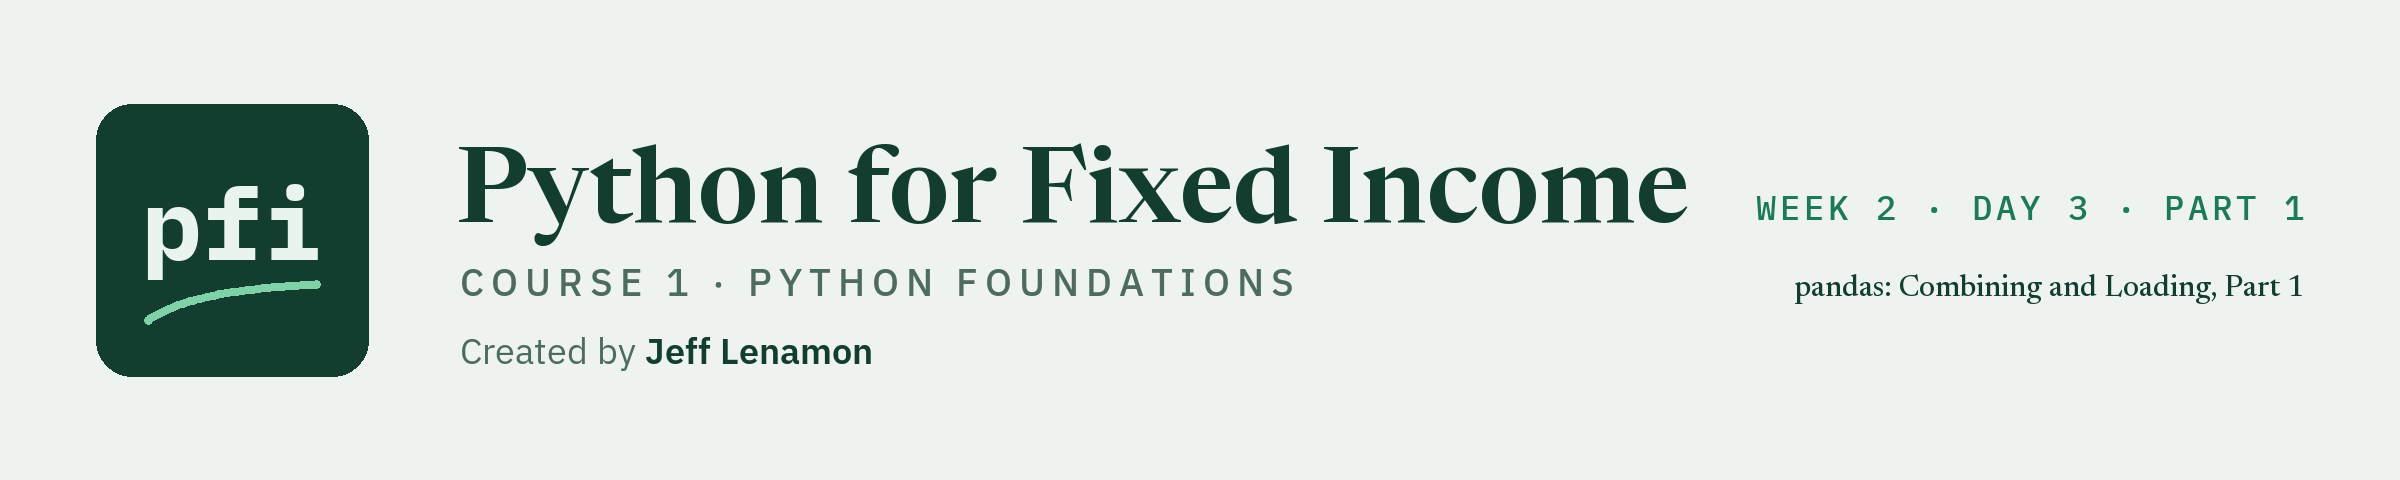

# pandas: Combining and Loading, Part 1

Week 2, Day 3, Part 1. Joining the desk's tables together, stacking them, and summarizing by group.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day3/08_pandas_combining_and_loading.ipynb)

## Before You Start: Install the Libraries

Run this cell first.

It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab.

If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course01_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


Yesterday the desk worked with one table, and everything it needed was already in it.

That is not how data usually arrives.

The positions come from one system, the issuer details from another, and the rating scale from a third.

The benchmark is a file of its own.

Today is about putting tables together and getting answers out of the result.

This notebook joins two tables on a shared column, stacks tables on top of each other, and summarizes the book by sector and rating.

These are the files, all in the `data` folder of the course repo.

The issuers are invented.

<table align="left">
<tr><th align="left">File</th><th align="left">Rows</th><th align="left">What it holds</th></tr>
<tr><td align="left"><code>positions.csv</code></td><td align="left">200 bonds</td><td align="left">what the desk holds: CUSIP, ticker, coupon, maturity, price, face held</td></tr>
<tr><td align="left"><code>issuers.csv</code></td><td align="left">150 issuers</td><td align="left">issuer name, sector, country, and rating for each ticker</td></tr>
<tr><td align="left"><code>ratings.csv</code></td><td align="left">18 ratings</td><td align="left">a numeric score, a rating bucket, and a grade for each rating</td></tr>
<tr><td align="left"><code>holdings.csv</code></td><td align="left">200 bonds</td><td align="left">yesterday's file: the same 200 bonds with every column filled in</td></tr>
<tr><td align="left"><code>benchmark.csv</code></td><td align="left">821 bonds</td><td align="left">the benchmark the portfolio is measured against</td></tr>
</table>
<br clear="left">

## 8.1 The Desk's Files

Q. Import pandas and load the positions file. How large is it, and what do the first rows look like?

In [2]:
import os

import pandas as pd

# on your own machine the files are in the repo's data folder. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

# the file name is added to the folder to make the full location
positions = pd.read_csv(data_folder + 'positions.csv')
print(positions.shape)
positions.head(3)

(200, 6)


,cusip,ticker,coupon,maturity,price,par_held
0,99080CAE8,BEZE,7.000,2032-06-18,106.727,5000000
1,99049XAE2,BEZH,8.125,2029-04-17,97.556,250000
2,99039NAC0,BEZL,5.125,2030-06-03,98.730,1500000


(200, 6): 200 bonds and six columns.

This is the lean file a position system sends: what the bond is, where it is priced, and how much the desk holds.

`data_folder` holds the location of the folder, chosen once by the `if`.

Each file is then read as `data_folder + 'file name'`.

Joining two pieces of text with `+` is from week 1.

The file has a ticker and nothing else about the issuer: no name, no sector, no rating.

Q. Load the issuer file. Does any ticker appear in it more than once?

In [3]:
issuers = pd.read_csv(data_folder + 'issuers.csv')
print(issuers.shape)

# nunique(), from the last notebook
print('Distinct tickers:', issuers['ticker'].nunique())
issuers.head(3)

(150, 5)
Distinct tickers: 150


,ticker,issuer,sector,country,rating
0,QVNE,Quorvane Energy,Energy,US,BBB
1,DNMR,Dunmarrow Rail,Transportation,US,BB+
2,PLWK,Pellwick Paper,Materials,US,A-


150 rows and 150 distinct tickers, so each issuer is listed once.

That is what a table used for lookups needs.

The first three issuers are the first three tickers of week 1: QVNE, DNMR, and PLWK.

Q. Load the rating scale and show its first eleven rows.

In [4]:
ratings = pd.read_csv(data_folder + 'ratings.csv')
print(ratings.shape)
ratings.head(11)

(18, 4)


,rating,score,bucket,grade
0,AAA,1,AAA,Investment Grade
1,AA+,2,AA,Investment Grade
2,AA,3,AA,Investment Grade
3,AA-,4,AA,Investment Grade
4,A+,5,A,Investment Grade
5,A,6,A,Investment Grade
6,A-,7,A,Investment Grade
7,BBB+,8,BBB,Investment Grade
8,BBB,9,BBB,Investment Grade
9,BBB-,10,BBB,Investment Grade


Eighteen ratings, one row each.

`score` is the number we gave each rating in week 1: 1 for AAA, counting up as the rating goes down.

`bucket` groups the notches: AA+, AA, and AA- are all in the AA bucket.

`grade` is Investment Grade down to BBB-, score 10, and High Yield from BB+, score 11, in the last row shown.

Q. How many different tickers does the desk hold?

In [5]:
print('Tickers in the positions file:', positions['ticker'].nunique())

Tickers in the positions file: 115


115 tickers across 200 bonds.

The positions file has many rows per ticker, and the issuer file has one row per ticker.

That is the usual shape of a lookup: many on one side, one on the other.

## 8.2 merge: A Lookup Across Tables

In Excel the next step is a `VLOOKUP` on the ticker, filled down 200 rows, once for each column wanted.

In pandas it is one call to `merge`.

Q. Add the issuer name, the sector, and the rating to every position. How many rows go in, and how many come out?

In [6]:
# the columns to bring in, plus the ticker to match on
issuer_details = issuers[['ticker', 'issuer', 'sector', 'rating']]

# pd.merge() matches the rows of two tables on a shared column
named = pd.merge(positions, issuer_details, on='ticker')

print('Positions:', positions.shape)
print('Issuer details:', issuer_details.shape)
print('Merged:', named.shape)
named.head(3)

Positions: (200, 6)
Issuer details: (150, 4)
Merged: (200, 9)


,cusip,ticker,coupon,maturity,price,par_held,issuer,sector,rating
0,99080CAE8,BEZE,7.000,2032-06-18,106.727,5000000,Bezane Finance,Financials,BBB-
1,99049XAE2,BEZH,8.125,2029-04-17,97.556,250000,Bezamyth Machinery,Industrials,B
2,99039NAC0,BEZL,5.125,2030-06-03,98.730,1500000,Bezoquil Freight,Transportation,BB


`pd.merge(left, right, on='ticker')` takes each row of the left table, finds the row of the right table with the same ticker, and puts the two side by side.

`on=` names the column to match on, called the **key**.

It appears once in the result.

200 rows went in and 200 came out, and the table grew from six columns to nine.

The first position, BEZE, now carries Bezane Finance, Financials, and BBB-.

Always print the row count after a merge.

The count can change without any error: rows are dropped when a key has no match, and rows are repeated when a key is listed twice in the lookup table.

Either one changes every total that follows.

**Predict 1**

The rating scale is keyed on the rating.

The next cell tries to join the positions to it directly:

```
pd.merge(positions, ratings, on='rating')
```

What do you expect?

> A) 200 rows, with the score, the bucket, and the grade added.
>
> B) Fewer than 200 rows, because some ratings find no match.
>
> C) An error.

Decide, then run the cell.

In [7]:
# join the positions to the rating scale on the rating
pd.merge(positions, ratings, on='rating')

KeyError: 'rating'

The answer is C. A `KeyError: 'rating'`.

The key has to exist in both tables under the same name, and `positions` has no `rating` column.

The rating arrived with the issuer details, so the table to use is `named`.

When a merge raises a `KeyError`, print the `columns` of both tables and compare the names.

Sometimes the key has a different name in each table.

Q. The issuer file calls its key `issuer_ticker`. How do we merge on it?

**Predict 2**

With `on='ticker'` the key appeared once, and six columns plus three more made nine.

In the next cell the key has a different name on each side:

```
pd.merge(positions, other_names, left_on='ticker', right_on='issuer_ticker')
```

How many columns will the result have?

> A) Nine.
>
> B) Ten.

Decide, then run the cell.

In [8]:
# rename() makes the key's name different for this example
other_names = issuer_details.rename(columns={'ticker': 'issuer_ticker'})

# left_on= names the key in the left table, and right_on= names it in the right table
different_keys = pd.merge(positions, other_names, left_on='ticker', right_on='issuer_ticker')
print(different_keys.shape)

(200, 10)


The answer is B: 200 rows again, and ten columns.

Both key columns stay in the result, because they have different names.

Q. Add the score and the grade of each rating to the table.

In [9]:
# match each position's rating to the rating scale
rated = pd.merge(named, ratings[['rating', 'score', 'grade']], on='rating')

print('Merged:', rated.shape)
rated[['ticker', 'issuer', 'rating', 'score', 'grade']].head(3)

Merged: (200, 11)


,ticker,issuer,rating,score,grade
0,BEZE,Bezane Finance,BBB-,10,Investment Grade
1,BEZH,Bezamyth Machinery,B,15,High Yield
2,BEZL,Bezoquil Freight,BB,12,High Yield


Still 200 rows, now with eleven columns.

BEZE, rated BBB-, has a score of 10 and is Investment Grade.

BEZH, rated B, has a score of 15 and is High Yield.

Two merges in a row: positions to issuers on the ticker, then the result to the rating scale on the rating.

Each one is a lookup from a different table.

Yesterday, sorting by rating gave alphabetical order, with AAA in seventh place.

The score fixes that.

Q. List the ratings the desk holds, in credit order.

In [10]:
# sort by the numeric score, then list each rating once
in_credit_order = rated.sort_values('score')
print(in_credit_order['rating'].unique().tolist())

['AAA', 'AA+', 'AA', 'AA-', 'A+', 'A', 'A-', 'BBB+', 'BBB', 'BBB-', 'BB+', 'BB', 'BB-', 'B+', 'B', 'B-', 'CCC+', 'CCC']


AAA first, then AA+, AA, AA-, and so on down to CCC.

A number sorts the way a rating should.

Text does not.

Q. How many positions are investment grade, and how many are high yield?

In [11]:
rated['grade'].value_counts()

grade
Investment Grade    128
High Yield           72
Name: count, dtype: int64

128 investment grade positions and 72 high yield.

Yesterday's file could not answer this, because the grade is not in it.

The answer came from joining three tables.

**Excel side by side.**

<table align="left">
<tr><th align="left">Step</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Bring in one column</td><td align="left"><code>pd.merge(positions, issuers[['ticker', 'sector']], on='ticker')</code></td><td align="left"><code>=VLOOKUP(B2, issuers!A:C, 3, FALSE)</code> filled down</td></tr>
<tr><td align="left">The same, without counting columns</td><td align="left">the same line</td><td align="left"><code>=XLOOKUP(B2, issuers!A:A, issuers!C:C)</code> in Microsoft 365 and Excel 2021 or later, or <code>INDEX</code> and <code>MATCH</code> in any version</td></tr>
<tr><td align="left">Bring in three columns</td><td align="left">one <code>merge</code> with three columns in the list</td><td align="left">three formulas, each filled down</td></tr>
<tr><td align="left">A key with no match</td><td align="left">the row is dropped, or kept with a blank, depending on the merge</td><td align="left"><code>#N/A</code></td></tr>
</table>
<br clear="left">

The Excel formulas assume the ticker in column B of the positions sheet, and an `issuers` sheet with the ticker in column A and the sector in column C. `merge` brings in every column in one step and names the key.

`VLOOKUP` brings in one column at a time and counts to it.

## 8.3 Inner, Left, Right, and Outer

In the last section every ticker found a match.

When some keys have no match, the `how=` argument decides which rows are kept.

The difference is easiest to see on two small tables made by hand.

Q. Make a table of the four week 1 positions, and a sector table that is missing one of them and has one extra ticker.

In [12]:
# the desk's four bonds
desk_small = pd.DataFrame({
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'face': [1500000, 500000, 750000, 250000],
})

# a sector table with no row for HLVF, and a row for THAR, which the desk does not hold
sector_small = pd.DataFrame({
    'ticker': ['QVNE', 'DNMR', 'PLWK', 'THAR'],
    'sector': ['Energy', 'Transportation', 'Materials', 'Materials'],
})

print(desk_small)
print()
print(sector_small)

  ticker     face
0   QVNE  1500000
1   DNMR   500000
2   PLWK   750000
3   HLVF   250000

  ticker          sector
0   QVNE          Energy
1   DNMR  Transportation
2   PLWK       Materials
3   THAR       Materials


Three tickers are in both tables.

HLVF is only in the desk's table, and THAR is only in the sector table.

Q. Merge the two tables without saying how.

In [13]:
# how='inner' is the default: keep only the keys found in both tables
pd.merge(desk_small, sector_small, on='ticker', how='inner')

,ticker,face,sector
0,QVNE,1500000,Energy
1,DNMR,500000,Transportation
2,PLWK,750000,Materials


The result has three rows.

HLVF and THAR are both gone, with no warning.

An **inner** merge keeps a row only when its key is in both tables.

This is the quiet way to lose a position: 250,000 of face disappeared from the table, and nothing said so.

Q. Keep every row of the desk's table, matched or not.

In [14]:
# how='left' keeps every row of the left table
left_join = pd.merge(desk_small, sector_small, on='ticker', how='left')
left_join

,ticker,face,sector
0,QVNE,1500000,Energy
1,DNMR,500000,Transportation
2,PLWK,750000,Materials
3,HLVF,250000,NaN


The result has four rows.

HLVF is kept, and its sector shows as `NaN`, the missing-value mark from yesterday.

THAR is not in the result, because it is not in the left table.

A **left** merge is the closest match to a `VLOOKUP`: every row of your table stays, and a failed lookup leaves a gap in place of `#N/A`.

For adding details to a list of positions it is the safe choice.

Q. Which of the desk's bonds found no sector?

In [15]:
# isna() is True where a value is missing
no_sector = left_join['sector'].isna()
print('Rows with no match:', no_sector.sum())
left_join[no_sector]

Rows with no match: 1


,ticker,face,sector
3,HLVF,250000,NaN


One row, HLVF.

`isna()` returns a mask, so it filters and counts like any condition from the last notebook.

`notna()` is its opposite.

Q. Now keep every row of the sector table.

In [16]:
# how='right' keeps every row of the right table
pd.merge(desk_small, sector_small, on='ticker', how='right')

,ticker,face,sector
0,QVNE,1500000.0,Energy
1,DNMR,500000.0,Transportation
2,PLWK,750000.0,Materials
3,THAR,NaN,Materials


Four rows again, but a different four.

THAR is kept with a missing face amount, and HLVF is gone.

The face column now shows a decimal point: 1500000.0.

A whole-number column cannot hold `NaN`, so pandas changed the column to `float64` to make room for the gap.

Q. Keep every row of both tables, and show where each row came from.

In [17]:
# how='outer' keeps every key from either table. indicator=True adds a column that says where each row was found.
pd.merge(desk_small, sector_small, on='ticker', how='outer', indicator=True)

,ticker,face,sector,_merge
0,DNMR,500000.0,Transportation,both
1,HLVF,250000.0,NaN,left_only
2,PLWK,750000.0,Materials,both
3,QVNE,1500000.0,Energy,both
4,THAR,NaN,Materials,right_only


Five rows: the three matches, HLVF, and THAR.

The rows come out sorted by ticker.

The `_merge` column reads `both` for a match, `left_only` for a key found only in the left table, and `right_only` for a key found only in the right table.

It is the quickest way to see what did not match.

<table align="left">
<tr><th align="left"><code>how=</code></th><th align="left">Rows kept</th><th align="left">Rows here</th></tr>
<tr><td align="left"><code>'inner'</code> (the default)</td><td align="left">keys found in both tables</td><td align="left">3</td></tr>
<tr><td align="left"><code>'left'</code></td><td align="left">every row of the left table</td><td align="left">4</td></tr>
<tr><td align="left"><code>'right'</code></td><td align="left">every row of the right table</td><td align="left">4</td></tr>
<tr><td align="left"><code>'outer'</code></td><td align="left">every key from either table</td><td align="left">5</td></tr>
</table>
<br clear="left">

Q. Draw the four merges side by side, so the difference can be seen at a glance.

As before, you do not need to study this chart's code today.

Run it and read the picture.

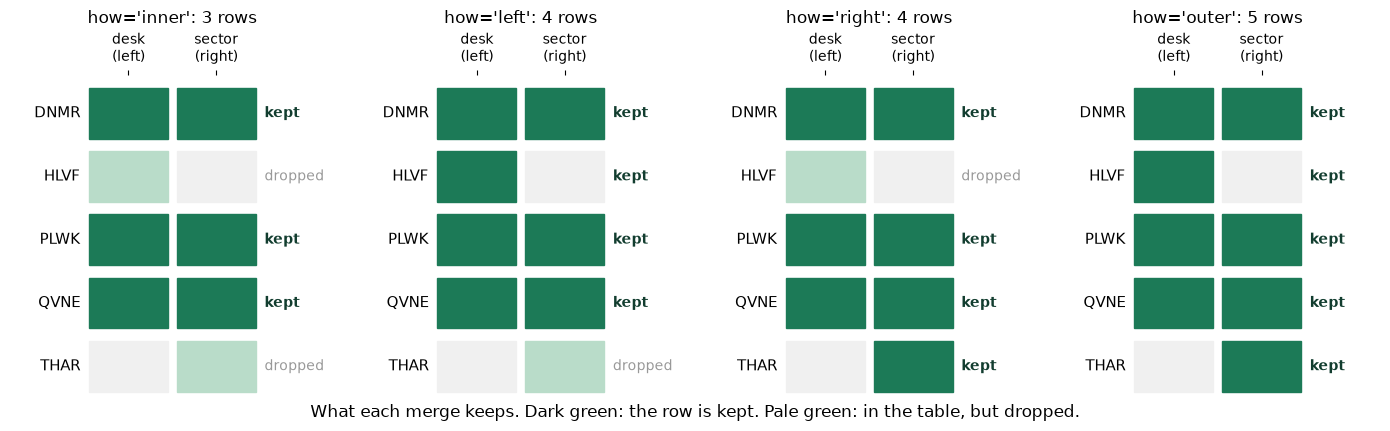

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# every ticker found in either table, in alphabetical order
all_tickers = sorted(set(desk_small['ticker']) | set(sector_small['ticker']))

# one panel for each value of how=
fig, axes = plt.subplots(1, 4, figsize=(14, 4.5))

for ax, how in zip(axes, ['inner', 'left', 'right', 'outer']):
    # run the real merge, and note which tickers it kept
    kept = set(pd.merge(desk_small, sector_small, on='ticker', how=how)['ticker'])

    for row, ticker in enumerate(all_tickers):
        y = len(all_tickers) - row          # the first ticker goes at the top
        is_kept = ticker in kept

        # two boxes per ticker: is it in the desk's table, and is it in the sector table?
        for column, table in enumerate([desk_small, sector_small]):
            in_table = ticker in set(table['ticker'])
            if in_table and is_kept:
                colour = '#1c7a57'          # in this table, and kept
            elif in_table:
                colour = '#b9dcc9'          # in this table, but the merge dropped the row
            else:
                colour = '#f0f0f0'          # not in this table at all
            ax.add_patch(Rectangle((column, y), 0.9, 0.8, color=colour))

        # the ticker on the left, and what happened to its row on the right
        ax.text(-0.1, y + 0.4, ticker, ha='right', va='center', fontsize=11)
        ax.text(2.0, y + 0.4, 'kept' if is_kept else 'dropped', va='center', fontsize=10,
                color='#123d2f' if is_kept else '#999999', fontweight='bold' if is_kept else 'normal')

    ax.set_title(f"how='{how}': {len(kept)} rows")
    ax.set_xlim(-0.9, 2.8)
    ax.set_ylim(0.9, len(all_tickers) + 1)
    # label the two columns of boxes at the top: the left table and the right table
    ax.xaxis.tick_top()
    ax.set_xticks([0.45, 1.45], ['desk\n(left)', 'sector\n(right)'])
    ax.set_yticks([])
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)

fig.suptitle('What each merge keeps. Dark green: the row is kept. Pale green: in the table, but dropped.',
             fontsize=12, y=0.02)
plt.tight_layout()
plt.show()

Read one row across the four panels.

QVNE, DNMR, and PLWK are in both tables, so every merge keeps them.

HLVF is only in the desk's table, the left one.

`left` and `outer` keep it; `inner` and `right` drop it.

THAR is only in the sector table, the right one.

`right` and `outer` keep it; `inner` and `left` drop it.

The rule in one line: `inner` keeps what both tables share, `left` keeps all of yours, `right` keeps all of theirs, `outer` keeps everything.

For adding details to a list of positions, use `left`, so no position can disappear.

A merge can also add rows.

Suppose the sector table lists one ticker twice.

Q. Merge the desk's table with a sector table that has two rows for QVNE. What happens to the total face?

In [19]:
# QVNE appears twice in this lookup table
sector_twice = pd.DataFrame({
    'ticker': ['QVNE', 'QVNE', 'DNMR', 'PLWK', 'HLVF'],
    'sector': ['Energy', 'Energy', 'Transportation', 'Materials', 'Consumer'],
})

doubled = pd.merge(desk_small, sector_twice, on='ticker', how='left')
print(doubled)
print()
print('Face before the merge:', desk_small['face'].sum())
print('Face after the merge:', doubled['face'].sum())

  ticker     face          sector
0   QVNE  1500000          Energy
1   QVNE  1500000          Energy
2   DNMR   500000  Transportation
3   PLWK   750000       Materials
4   HLVF   250000        Consumer

Face before the merge: 3000000
Face after the merge: 4500000


Five rows from a four-row table.

The QVNE position matched both QVNE rows of the lookup table, so it appears twice, and the total face went from 3,000,000 to 4,500,000.

There was no error.

The only sign is the row count, which is why it is checked after every merge.

The cure is a lookup table with each key once, which `nunique()` confirmed for the issuer file in section 8.1.

pandas can make that check itself, as part of the merge.

Q. Ask `merge` to refuse a lookup table that lists a key twice.

In [20]:
# validate='many_to_one' says: many rows on the left may share a key, and the right table must list each key once
pd.merge(desk_small, sector_twice, on='ticker', how='left', validate='many_to_one')

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 ticker
  QVNE ...

A `MergeError`.

Go to the end of the traceback: 'Merge keys are not unique in right dataset; not a many-to-one merge'.

The wording differs a little between versions of pandas, and this version also names the key that repeats, QVNE.

This time the merge stopped.

No table came back, so nothing was doubled.

`validate=` states the shape the lookup is meant to have, and pandas tests it before joining.

`'many_to_one'` is the shape of every lookup in this course: many positions on the left, one row per key on the right.

Q. Run the same guard on the real lookup, the issuer details.

In [21]:
# the issuer details list each ticker once, so the guard passes and the merge runs
guarded = pd.merge(positions, issuer_details, on='ticker', how='left', validate='many_to_one')

# the rule from Day 3 of week 1: a check that matters is an assert
assert guarded.shape[0] == positions.shape[0], 'the merge changed the row count'
print(f'Rows in: {positions.shape[0]:,}  rows out: {guarded.shape[0]:,}')

Rows in: 200  rows out: 200


No error: 200 rows in and 200 out.

A guard that passes prints nothing, and neither does an `assert` that passes.

`validate=` catches a repeated key.

It does not catch a key with no match, so the row count and the `isna()` count still have their job.

Written into the code, both checks run every time the notebook is run again on a new file.

Nobody has to remember to look at a printed count.

Q. Back to the real files. Did every one of the 200 positions find its issuer?

In [22]:
# a left merge keeps all 200 positions, and the indicator shows which ones matched
matched = pd.merge(positions, issuer_details, on='ticker', how='left', indicator=True)

print('Rows:', matched.shape[0])
matched['_merge'].value_counts()

Rows: 200


_merge
both          200
left_only       0
right_only      0
Name: count, dtype: int64

200 rows, and all 200 read `both`.

No position is missing an issuer, so the inner merge in section 8.2 dropped nothing.

**Excel side by side.** A left merge is `VLOOKUP` filled down: every row of the sheet stays and a failed lookup shows `#N/A`.

Finding the failures is `=ISNA(...)` in Excel and `isna()` in pandas.

For an inner or an outer merge, Excel's closest tool is Power Query: Merge Queries offers the Join Kinds Inner, Left Outer, Right Outer, and Full Outer, which are the four values of `how=`.

`VLOOKUP` returns the first match it finds and gives no sign of a second one.

The test for a repeated key in Excel is a helper column on the lookup sheet, `=COUNTIF(A:A, A2)`, filtered for values above 1.

In pandas it is `validate='many_to_one'` inside the merge.

## 8.4 The Portfolio Against the Benchmark

The same tool answers a question every desk asks: which bonds of the benchmark does the portfolio hold?

Both files identify a bond by its CUSIP, so the CUSIP is the key.

Q. Load the full holdings file and the benchmark file. How large is each?

In [23]:
holdings = pd.read_csv(data_folder + 'holdings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')

print('Holdings:', holdings.shape)
print('Benchmark:', benchmark.shape)
print('Sum of the benchmark weights:', round(benchmark['weight_pct'].sum(), 2))

Holdings: (200, 19)
Benchmark: (821, 19)


Sum of the benchmark weights: 100.0


The holdings file has 200 bonds and the benchmark has 821.

Both have 19 columns.

Where the holdings have `par_held`, the benchmark has `weight_pct`: the weight of each bond in the benchmark, in percent.

The weights add up to 100.

Q. Mark each benchmark bond with the face the desk holds in it.

In [24]:
# the benchmark is the left table, so all 821 of its bonds are kept
desk_face = holdings[['cusip', 'par_held']]
compared = pd.merge(benchmark, desk_face, on='cusip', how='left')

print('Rows:', compared.shape[0])
compared[['cusip', 'ticker', 'sector', 'weight_pct', 'par_held']].head(4)

Rows: 821


,cusip,ticker,sector,weight_pct,par_held
0,99001BAA4,QVNE,Energy,0.2076,2750000.0
1,99001BAB2,QVNE,Energy,0.1551,NaN
2,99001BAC0,QVNE,Energy,0.0245,NaN
3,99001BAD8,QVNE,Energy,0.2024,NaN


821 rows, one per benchmark bond.

`par_held` is filled in where the desk holds the bond and is `NaN` where it does not.

Of the four QVNE bonds shown, the desk holds the first, with 2,750,000 of face.

We passed two columns of the holdings: the key and the one column wanted.

**Predict 3**

The benchmark and the holdings both have a `price` column, as well as the key:

```
same_name = pd.merge(benchmark[['cusip', 'price']], holdings[['cusip', 'price']], on='cusip')
```

What do you expect?

> A) An error, because a table cannot hold two columns with one name.
>
> B) One `price` column, taken from the left table.
>
> C) Two price columns, under new names.

Decide, then run the cell.

In [25]:
# both tables have a price column, as well as the key
same_name = pd.merge(benchmark[['cusip', 'price']], holdings[['cusip', 'price']], on='cusip')
same_name.head(2)

,cusip,price_x,price_y
0,99001BAA4,98.882,98.882
1,99001BAF3,91.884,91.884


The answer is C. pandas keeps both and renames them: `price_x` from the left table and `price_y` from the right.

Q. How many benchmark bonds does the portfolio hold, and what share of the benchmark's weight are they?

In [26]:
# a missing face amount means the desk does not hold the bond
not_held = compared['par_held'].isna()
held = compared['par_held'].notna()

print('Held:', held.sum())
print('Not held:', not_held.sum())
print('Benchmark weight of the bonds held:', round(compared.loc[held, 'weight_pct'].sum(), 2))
print('Benchmark weight of the bonds not held:', round(compared.loc[not_held, 'weight_pct'].sum(), 2))

Held: 200
Not held: 621
Benchmark weight of the bonds held: 24.56
Benchmark weight of the bonds not held: 75.44


The portfolio holds 200 of the benchmark's 821 bonds and does not hold the other 621.

The 200 bonds held make up 24.56 percent of the benchmark by weight.

The 621 not held make up 75.44 percent.

Q. Does the portfolio hold anything that is not in the benchmark?

In [27]:
# an outer merge keeps every CUSIP from either file
both_files = pd.merge(benchmark, desk_face, on='cusip', how='outer', indicator=True)
both_files['_merge'].value_counts()

_merge
left_only     621
both          200
right_only      0
Name: count, dtype: int64

621 bonds are `left_only`, in the benchmark alone.

200 are in both files.

None is `right_only`, so every bond the desk holds is a benchmark bond.

These are counts and weights and nothing more.

They describe where the two files overlap.

**Excel side by side.** In Excel this is a helper column on the benchmark sheet: `=COUNTIF(holdings!B:B, B2)` gives 1 for a bond the desk holds and 0 for one it does not, and `=SUMIF(T:T, 1, S:S)` adds up the weights of the bonds held, with the helper in column T and the weight in column S. The pandas version is the left merge, followed by `isna()`.

## 8.5 Stacking Tables With concat

`merge` puts tables side by side and adds columns.

The other way to combine tables is to stack them and add rows.

First, a table worth stacking.

Q. Add the score, the bucket, and the grade to the full holdings file. Call the result `book`.

In [28]:
# holdings.csv already has the rating of each bond, so one merge is enough
book = pd.merge(holdings, ratings, on='rating')
print(book.shape)

(200, 22)


(200, 22): the 19 columns of the holdings plus `score`, `bucket`, and `grade`.

`book` is the table for the rest of the lesson.

Suppose the investment grade and the high yield positions are kept by two different traders and arrive as two tables.

Q. Split the book into its investment grade and high yield rows, then put the two parts back together.

In [29]:
# the two parts, as they might arrive from two traders
ig_book = book[book['grade'] == 'Investment Grade']
hy_book = book[book['grade'] == 'High Yield']
print('Investment grade:', ig_book.shape)
print('High yield:', hy_book.shape)

# pd.concat() stacks a list of tables on top of each other
stacked = pd.concat([ig_book, hy_book])
print('Stacked:', stacked.shape)
print('Market value:', stacked['market_value'].sum())

Investment grade: (128, 22)
High yield: (72, 22)
Stacked: (200, 22)
Market value: 490819215.0


128 rows and 72 rows stack into 200.

The columns are the same 22, and the market value is 490,819,215, the total from the last notebook.

Nothing was lost or repeated.

`pd.concat()` takes a list of tables, in square brackets, and lines the columns up by name.

A column that is missing from one of the tables is filled with `NaN` for that table's rows.

Q. What are the row labels where the first table ends and the second begins?

In [30]:
# rows 126 to 129 of the stacked table: the last two investment grade rows and the first two high yield rows
print(stacked.index[126:130].tolist())

# ignore_index=True throws the old labels away and numbers the rows again from 0
stacked = pd.concat([ig_book, hy_book], ignore_index=True)
print(stacked.index[126:130].tolist())

[198, 199, 1, 2]
[126, 127, 128, 129]


Without `ignore_index`, each row keeps the label it had in `book`: 198 and 199 at the end of the investment grade rows, then 1 and 2 at the start of the high yield rows.

With `ignore_index=True` the labels are 126, 127, 128, 129: one clean run from 0 to 199.

It matters most when the tables each count from 0, such as two daily files.

Stacked as they are, the labels 0, 1, 2 would each appear twice, and `loc[0]` would return two rows.

Q. Two systems each send one column for the first three bonds: the price from one and the spread from the other. Put them side by side.

In [31]:
price_part = book[['ticker', 'price']].head(3)
oas_part = book[['oas']].head(3)

# axis=1 puts the tables side by side, matching the rows by their labels
print(pd.concat([price_part, oas_part], axis=1))

  ticker    price  oas
0   BEZE  106.727  147
1   BEZH   97.556  535
2   BEZL   98.730  153


The two line up by row label, 0 to 2.

Q. What if the second table covers rows 1 to 3 instead?

In [32]:
oas_shifted = book[['oas']].iloc[1:4]
print(pd.concat([price_part, oas_shifted], axis=1))

  ticker    price    oas
0   BEZE  106.727    NaN
1   BEZH   97.556  535.0
2   BEZL   98.730  153.0
3    NaN      NaN  218.0


Row 0 has a price and no spread, and row 3 has a spread and no price: `NaN` fills each gap.

`axis=0`, the default, stacks tables on top of each other.

`axis=1` places them side by side.

With `axis=1` the match is made on the row labels, not on a key column.

When the match should be on a column such as the ticker or the CUSIP, use `merge`.

**Excel side by side.** `concat` is copying one sheet and pasting it under another, or `=VSTACK(range1, range2)` in Microsoft 365 and Excel 2024, and `=HSTACK(range1, range2)` is the `axis=1` version.

Excel pastes by position, so the columns must be in the same order. pandas matches the columns by name.

## 8.6 Summarizing by Group

A list of 200 bonds is not a report.

The desk wants totals and averages by sector, by rating, by grade.

In Excel that is a pivot table.

In pandas it is `groupby`.

Q. What is the market value of the portfolio in each sector?

In [33]:
# groupby() splits the rows into one group per sector, then sum() adds up the chosen column in each group
sector_value = book.groupby('sector')['market_value'].sum()

# a Series has no .style, so to_frame() makes it a one-column table first
sector_value.to_frame('Market value').style.format('{:,.1f}').set_caption('Market value by sector')

,Market value
sector,
Consumer,"56,629,597.5"
Energy,"38,830,005.0"
Financials,"68,219,672.5"
Health Care,"38,908,187.5"
Industrials,"52,540,745.0"
Materials,"71,701,617.5"
Technology,"30,311,760.0"
Telecom,"55,848,270.0"
Transportation,"48,822,897.5"


Ten sectors, one total each, in alphabetical order.

Energy is 38,830,005, the figure we found yesterday with a filter.

`groupby` does that filter for every sector at once.

Read the line in three parts: `groupby('sector')` says how to split the rows, `['market_value']` picks the column, and `sum()` is the calculation.

Any of the statistics from the last notebook can take the place of `sum()`.

The result is a Series, and its index is the sector.

It is shown as a styled table, the `.style` of section 7.10, with thousands commas and a caption.

Q. Which three sectors hold the most market value?

In [34]:
# a grouped result is a Series, so it sorts like one
top_three = sector_value.sort_values(ascending=False).head(3)
print(top_three)

# the index of the result holds the sector names
print(top_three.index.tolist())

sector
Materials     71701617.5
Financials    68219672.5
Consumer      56629597.5
Name: market_value, dtype: float64
['Materials', 'Financials', 'Consumer']


Materials at 71,701,617.5, Financials at 68,219,672.5, and Consumer at 56,629,597.5.

Those are the three sectors with 26 bonds each.

`index.tolist()` gives the group names as a plain list.

`sort_values()` then `head()` on one line is called **method chaining**.

Each method returns a new object, so the next one can be written straight after it.

Read the line from left to right.

Q. What is the average OAS in each rating bucket?

In [35]:
bucket_oas = book.groupby('bucket')['oas'].mean()

# loc with a list of labels puts the buckets in credit order
credit_order = ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC']
(bucket_oas.loc[credit_order].to_frame('Average OAS (bp)')
    .style.format('{:,.2f}')
    .background_gradient(cmap='Greens')
    .set_caption('Average OAS by rating bucket'))

,Average OAS (bp)
bucket,
AAA,21.00
AA,37.62
A,79.41
BBB,127.82
BB,226.22
B,503.33
CCC,858.00


The average OAS is 21 basis points for AAA, 37.62 for AA, 79.41 for A, 127.82 for BBB, 226.22 for BB, 503.33 for B, and 858 for CCC.

Each step down in rating bucket has a higher average spread than the one before.

The A figure, 79.41, is the single-A average from the last notebook, which took an `isin()` with three ratings.

With the bucket column it is one group among seven.

`groupby` sorts the groups alphabetically.

The `loc` line puts them in the order the desk reads them.

Q. For investment grade and for high yield, show the number of bonds and the mean, median, lowest, and highest OAS.

In [36]:
# agg() takes a list of statistics and returns one column for each
grade_oas = book.groupby('grade')['oas'].agg(['count', 'mean', 'median', 'min', 'max'])
grade_oas.style.format({'mean': '{:,.2f}', 'median': '{:,.1f}'}).set_caption('OAS by grade, in bp')

,count,mean,median,min,max
grade,,,,,
High Yield,72,339.38,250.5,125,1551
Investment Grade,128,99.34,95.0,19,204


The 128 investment grade bonds have a mean OAS of about 99.34 basis points and a median of 95, and run from 19 to 204.

The 72 high yield bonds have a mean of 339.38 and a median of 250.5, and run from 125 to 1,551.

The mean is well above the median, so a few very wide bonds are pulling it up.

The result of `agg()` with a list is a DataFrame: one row per group, one column per statistic.

Q. Build a sector summary: the number of bonds, the market value, the average OAS, and the average duration.

In [37]:
# each line reads: new column name = (column to use, statistic)
sector_summary = book.groupby('sector').agg(
    bonds=('cusip', 'count'),
    market_value=('market_value', 'sum'),
    avg_oas=('oas', 'mean'),
    avg_duration=('duration', 'mean'),
)
sector_summary = sector_summary.round(2)

(sector_summary.style
    .format({'market_value': '{:,.0f}', 'avg_oas': '{:,.2f}', 'avg_duration': '{:,.2f}'})
    .background_gradient(subset=['avg_oas'], cmap='Greens')
    .set_caption('Sector summary'))

,bonds,market_value,avg_oas,avg_duration
sector,,,,
Consumer,26,"56,629,598",218.88,6.84
Energy,17,"38,830,005",171.59,6.97
Financials,26,"68,219,672",172.31,6.15
Health Care,20,"38,908,188",141.75,5.87
Industrials,20,"52,540,745",220.55,6.33
Materials,26,"71,701,618",182.42,5.61
Technology,12,"30,311,760",298.17,5.75
Telecom,21,"55,848,270",182.38,6.35
Transportation,20,"48,822,898",126.50,8.19


One row per sector and four columns, each from a different column of the book with its own statistic.

This is the table a pivot table would give.

Technology has the highest average OAS, 298.17 basis points, on 12 bonds.

Transportation has the lowest, 126.5, and the longest average duration, 8.19 years.

These averages count every bond equally, whatever its size.

**Excel side by side.**

<table align="left">
<tr><th align="left">Question</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Market value of one sector</td><td align="left"><code>sector_value.loc['Energy']</code></td><td align="left"><code>=SUMIF(E:E, "Energy", S:S)</code></td></tr>
<tr><td align="left">Average OAS of one sector</td><td align="left"><code>book.groupby('sector')['oas'].mean().loc['Energy']</code></td><td align="left"><code>=AVERAGEIF(E:E, "Energy", M:M)</code></td></tr>
<tr><td align="left">Bonds in one sector</td><td align="left"><code>book.groupby('sector')['cusip'].count().loc['Energy']</code></td><td align="left"><code>=COUNTIF(E:E, "Energy")</code></td></tr>
<tr><td align="left">Every sector at once</td><td align="left"><code>book.groupby('sector')['market_value'].sum()</code></td><td align="left">a pivot table: sector in Rows, Sum of market_value in Values</td></tr>
<tr><td align="left">Several statistics at once</td><td align="left"><code>agg(...)</code></td><td align="left">more fields dragged into Values</td></tr>
</table>
<br clear="left">

The columns are as in `holdings.csv`: sector in E, OAS in M, market value in S.

## You Can Now

By the end of this notebook, you can:

* Join a position file to an issuer file and a rating scale, the job `VLOOKUP` does, and check the row count so that no position is dropped or doubled
* Choose between `inner`, `left`, `right`, and `outer`, and find what did not match
* Guard a merge with `validate='many_to_one'`, so that a repeated key in the lookup stops the merge
* Compare a portfolio with its benchmark by CUSIP: how many benchmark bonds are held and what weight they carry
* Stack tables with `concat`, and put them side by side with `axis=1`
* Summarize a portfolio by sector, rating bucket, or grade, with counts, totals, and averages

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use the holdings file, the benchmark file, and the rating scale, with questions the lesson did not ask.

The issuers are invented.

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first.

It imports pandas, loads fresh copies of the three files as `holdings`, `ratings`, and `benchmark`, and defines `check`, a small function that marks your answers.

It allows for tiny rounding differences in numbers with a decimal point.

In [38]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# fresh copies of three files. In Colab they are read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'

holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
benchmark = pd.read_csv(data_folder + 'benchmark.csv')
print(holdings.shape, ratings.shape, benchmark.shape)

(200, 19) (18, 4) (821, 19)


### Exercise 1

Q. Merge the benchmark with the rating scale. How many benchmark bonds are High Yield, and what is their total weight in the benchmark, in percent, rounded to one decimal place? Store the answers in **ex1_count** and **ex1_weight**.

In [39]:
ex1_count = ...
ex1_weight = ...

In [40]:
check('Exercise 1 count', ex1_count, 281)
check('Exercise 1 weight', ex1_weight, 34.4)

Exercise 1 count: not attempted yet
Exercise 1 weight: not attempted yet


### Exercise 2

Q. Merge the holdings with the rating scale, and total the face held in each rating bucket. How much face does the desk hold in the BBB bucket? Which three buckets have the most face, largest first? Store the answers in **ex2_bbb_face** and, as a list, in **ex2_top_buckets**.

In [41]:
ex2_bbb_face = ...
ex2_top_buckets = ...

In [42]:
check('Exercise 2 BBB face', ex2_bbb_face, 151750000)
check('Exercise 2 top buckets', ex2_top_buckets, ['BBB', 'A', 'BB'])

Exercise 2 BBB face: not attempted yet
Exercise 2 top buckets: not attempted yet


### Exercise 3

Q. Mark each benchmark bond with the face the desk holds in it, with a left merge on the CUSIP. Among the benchmark's Energy bonds, how many does the desk hold, and what is their benchmark weight, in percent, rounded to two decimal places? Store the answers in **ex3_count** and **ex3_weight**.

In [43]:
ex3_count = ...
ex3_weight = ...

In [44]:
check('Exercise 3 count', ex3_count, 17)
check('Exercise 3 weight', ex3_weight, 2.29)

Exercise 3 count: not attempted yet
Exercise 3 weight: not attempted yet


### Exercise 4

Q. Split the holdings into the bonds priced below 100 and the bonds priced at 100 or above. Store the number of bonds below 100 in **ex4_below**. Stack the two tables with `pd.concat()`, numbering the rows again from 0, and store the result in **ex4_stacked**. Then store its number of rows in **ex4_rows** and its total market value in **ex4_value**.

In [45]:
ex4_below = ...
ex4_stacked = ...
ex4_rows = ...
ex4_value = ...

In [46]:
check('Exercise 4 below 100', ex4_below, 113)
check('Exercise 4 rows', ex4_rows, 200)
check('Exercise 4 market value', ex4_value, 490819215.0)

Exercise 4 below 100: not attempted yet
Exercise 4 rows: not attempted yet
Exercise 4 market value: not attempted yet


### Exercise 5: AI check

You ask an AI assistant how many of the benchmark's Energy bonds the desk holds, and what benchmark weight they carry.

It gives you the code below.

It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. What numbers do you expect? You worked both out yourself in Exercise 3. Then run the code. Does it agree with you?

In [47]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ai_desk = holdings[['ticker', 'par_held']]
ai_compared = pd.merge(benchmark, ai_desk, on='ticker', how='left')

ai_held = ai_compared['par_held'].notna() & (ai_compared['sector'] == 'Energy')
ex5_count = ai_held.sum()
ex5_weight = round(ai_compared.loc[ai_held, 'weight_pct'].sum(), 2)

print(f'Energy bonds held: {ex5_count}')
print(f'Their benchmark weight: {ex5_weight}')

Energy bonds held: 96
Their benchmark weight: 12.2


Q. Find the bug and fix the code in the cell above, so that **ex5_count** and **ex5_weight** hold the right answers.

In [48]:
check('Exercise 5 count', ex5_count, 17)
check('Exercise 5 weight', ex5_weight, 2.29)

Exercise 5 count: not yet. You have 96
Exercise 5 weight: not yet. You have 12.2


## Congratulations!

You made it through the first half of a long day.

You joined tables that came from different systems, and you checked that no position was lost or doubled on the way.

You stacked tables, compared the book with its benchmark, and summarized it by sector and rating.

A `VLOOKUP` and a pivot table now have a written, repeatable twin that runs again next month on a new file.

Next is pandas: Combining and Loading, Part 2.

You report the weighted averages a desk actually quotes, save your results to a file and a workbook, and turn date text into a maturity profile.